# Détecteur et Classifieur d'Objets Spatiaux & Débris
Detecteur de Déchets 

Ce notebook prépare le pipeline complet de données avec **Pandas** et **TensorFlow**.
Chaque image contient un **unique objet** (satellite ou débris). Le pipeline génère ainsi deux cibles pour chaque image :
- `class_output` : l'identifiant de la classe (parmi 11 classes)
- `bbox_output` : les 4 coordonnées normalisées `[ymin, xmin, ymax, xmax]`

In [1]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf
import yaml

# Configuration globale
IMG_SIZE = 224
BATCH_SIZE = 16

DATA_YAML_PATH = 'data/data.yaml'
with open(DATA_YAML_PATH, 'r', encoding='utf-8') as yaml_file:
    dataset_config = yaml.safe_load(yaml_file)

ORIGINAL_CLASS_NAMES = dataset_config['names']
CLASS_NAMES = ['satellite', 'debris']
NUM_CLASSES = len(CLASS_NAMES)

print(f"TensorFlow version: {tf.__version__}")
print(f"Classes originales : {ORIGINAL_CLASS_NAMES}")
print(f"Classes du modèle : {CLASS_NAMES}")

I0000 00:00:1792230909.836743   25667 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792230909.867648   25667 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792230910.901590   25667 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.22.0-rc0
Classes originales : ['cheops', 'debris', 'double_start', 'earth_observation_sat_1', 'lisa_pathfinder', 'proba_2', 'proba_3_csc', 'proba_3_ocs', 'smart_1', 'soho', 'xmm_newton']
Classes du modèle : ['satellite', 'debris']


## 1. Préparation des DataFrames Pandas

Nous lisons les annotations YOLO (`[class_id, x_center, y_center, width, height]`) et les convertissons directement en `[ymin, xmin, ymax, xmax]`.
Chaque image contenant un unique objet, nous n'avons plus besoin de padding `MAX_BOXES`.


In [2]:
def create_dataset_dataframe(image_dir):
    """
    Lit les annotations YOLO et crée un DataFrame avec une cible binaire.
    Tous les objets sauf debris sont regroupés dans la classe satellite.
    """
    image_paths = sorted(glob.glob(os.path.join(image_dir, '*.jpg')))
    records = []

    for img_path in image_paths:
        label_path = img_path.replace('images', 'labels').replace('.jpg', '.txt')
        if os.path.exists(label_path):
            with open(label_path, 'r') as label_file:
                line = label_file.readline().strip()
                if line:
                    parts = line.split()
                    cls_id = int(parts[0])
                    x_c, y_c, box_width, box_height = map(float, parts[1:5])
                    original_class_name = (
                        ORIGINAL_CLASS_NAMES[cls_id]
                        if 0 <= cls_id < len(ORIGINAL_CLASS_NAMES)
                        else 'unknown'
                    )

                    ymin = max(0.0, y_c - (box_height / 2.0))
                    xmin = max(0.0, x_c - (box_width / 2.0))
                    ymax = min(1.0, y_c + (box_height / 2.0))
                    xmax = min(1.0, x_c + (box_width / 2.0))

                    binary_class_id = int(original_class_name == 'debris')
                    records.append({
                        'image_path': img_path,
                        'class_id': cls_id,
                        'class_name': original_class_name,
                        'binary_class_id': binary_class_id,
                        'binary_class_name': CLASS_NAMES[binary_class_id],
                        'ymin': ymin,
                        'xmin': xmin,
                        'ymax': ymax,
                        'xmax': xmax,
                    })

    return pd.DataFrame(records)

# Création des DataFrames
df_train = create_dataset_dataframe('data/train/images')
df_val = create_dataset_dataframe('data/valid/images')
df_test = create_dataset_dataframe('data/test/images')

print(f"Train : {len(df_train)} images")
print(f"Val   : {len(df_val)} images")
print(f"Test  : {len(df_test)} images")
print("Distribution binaire (Train) :")
print(df_train['binary_class_name'].value_counts())
df_train.head()

Train : 2105 images
Val   : 239 images
Test  : 123 images
Distribution binaire (Train) :
binary_class_name
satellite    1919
debris        186
Name: count, dtype: int64


,image_path,class_id,class_name,binary_class_id,binary_class_name,ymin,xmin,ymax,xmax
0,data/train/images/img000008_jpg.rf.2c95cb6fb03...,5,proba_2,0,satellite,0.369141,0.129297,0.865234,0.430078
1,data/train/images/img000008_jpg.rf.9f76dc15cc1...,5,proba_2,0,satellite,0.134766,0.129297,0.630859,0.430078
2,data/train/images/img000009_jpg.rf.1142d9cc183...,5,proba_2,0,satellite,0.341016,0.192578,0.969922,0.585547
3,data/train/images/img000009_jpg.rf.1c26d8ebd8e...,5,proba_2,0,satellite,0.341016,0.414453,0.969922,0.807422
4,data/train/images/img000009_jpg.rf.da7b45fe680...,5,proba_2,0,satellite,0.030078,0.192578,0.658984,0.585547


In [3]:
df_train

,image_path,class_id,class_name,binary_class_id,binary_class_name,ymin,xmin,ymax,xmax
0,data/train/images/img000008_jpg.rf.2c95cb6fb03...,5,proba_2,0,satellite,0.369141,0.129297,0.865234,0.430078
1,data/train/images/img000008_jpg.rf.9f76dc15cc1...,5,proba_2,0,satellite,0.134766,0.129297,0.630859,0.430078
2,data/train/images/img000009_jpg.rf.1142d9cc183...,5,proba_2,0,satellite,0.341016,0.192578,0.969922,0.585547
3,data/train/images/img000009_jpg.rf.1c26d8ebd8e...,5,proba_2,0,satellite,0.341016,0.414453,0.969922,0.807422
4,data/train/images/img000009_jpg.rf.da7b45fe680...,5,proba_2,0,satellite,0.030078,0.192578,0.658984,0.585547
...,...,...,...,...,...,...,...,...,...
2100,data/train/images/img101601_jpg.rf.685459b9385...,10,xmm_newton,0,satellite,0.001172,0.533203,0.492578,0.999609
2101,data/train/images/img101601_jpg.rf.e0f21b69e7c...,10,xmm_newton,0,satellite,0.001172,0.000391,0.492578,0.466797
2102,data/train/images/img101603_jpg.rf.58ceeb658d1...,10,xmm_newton,0,satellite,0.000000,0.473828,0.281250,0.965234
2103,data/train/images/img101603_jpg.rf.ac0a7663547...,10,xmm_newton,0,satellite,0.718750,0.034766,1.000000,0.526172


## 2. Exploration des données (EDA)
Vérifions la distribution des classes dans l'ensemble d'entraînement.


In [4]:
print("Distribution des classes binaires (Train) :")
print(df_train['binary_class_name'].value_counts())

Distribution des classes binaires (Train) :
binary_class_name
satellite    1919
debris        186
Name: count, dtype: int64


Lors de l'analyse des données, nous voyons qu'il est nécessaire de faire de l'équilNous voyons que nous avons beaucoup plus de sattelites que de débris, donc nous allons augmenter le nombre de débrs et faire un dossier avec 50% de satellites et 50% de débris. 

Pour cela, nous allons faire une rotation avec les images de débris, on en ajoute donc en faisant des rotations à 45, 60, 90, 180 et 270°. Ainsi, on multiplie la quantité de données que nous  les multiplie par 4 en les faisant tourner 

## 3. Pipeline TensorFlow (`tf.data`)

Nous transformons directement les DataFrames Pandas en `tf.data.Dataset` optimisés via `tf.data.Dataset.from_tensor_slices` :
- Chargement et décodage multithreadés (`AUTOTUNE`)
- Redimensionnement à `IMG_SIZE` et normalisation dans `[0, 1]`
- Sortie au format dictionnaire `{'class_output': ..., 'bbox_output': ...}` prêt pour un modèle multi-tâches (classification + localisation)


In [5]:
def df_to_tf_dataset(df, img_size=IMG_SIZE, batch_size=BATCH_SIZE, is_training=True):
    image_paths = df['image_path'].values
    bboxes = df[['ymin', 'xmin', 'ymax', 'xmax']].values.astype(np.float32)
    class_ids = df['binary_class_id'].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((image_paths, bboxes, class_ids))

    def load_and_preprocess(img_path, bbox, cls_id):
        img_raw = tf.io.read_file(img_path)
        img = tf.image.decode_jpeg(img_raw, channels=3)
        img = tf.image.resize(img, [img_size, img_size])
        img = tf.cast(img, tf.float32) / 255.0
        return img, {
            'class_output': cls_id,
            'bbox_output': bbox,
        }

    if is_training:
        dataset = dataset.shuffle(
            buffer_size=min(len(df), 1000),
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_ds = df_to_tf_dataset(df_train, is_training=True)
val_ds = df_to_tf_dataset(df_val, is_training=False)
test_ds = df_to_tf_dataset(df_test, is_training=False)

print("Datasets TensorFlow construits et prêts pour l'entraînement !")

Datasets TensorFlow construits et prêts pour l'entraînement !


E0000 00:00:1792230912.115447   25667 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



## 4. Visualisation d'un lot pour vérification
Affichons un lot d'entraînement avec l'étiquette de classe et la boîte englobante correspondante.


In [6]:
# for images, targets in train_ds.take(1):
#     fig, axes = plt.subplots(2, 4, figsize=(14, 7))
#     axes = axes.flatten()

#     for i in range(min(8, len(images))):
#         img = images[i].numpy()
#         cls_id = int(targets['class_output'][i].numpy())
#         ymin, xmin, ymax, xmax = targets['bbox_output'][i].numpy()

#         h, w, _ = img.shape
#         box_y = ymin * h
#         box_x = xmin * w
#         box_h = (ymax - ymin) * h
#         box_w = (xmax - xmin) * w

#         axes[i].imshow(img)
#         rect = patches.Rectangle((box_x, box_y), box_w, box_h, linewidth=2, edgecolor='lime', facecolor='none')
#         axes[i].add_patch(rect)
#         axes[i].set_title(f"{CLASS_NAMES[cls_id]}", color='white', backgroundcolor='black', fontsize=10)
#         axes[i].axis('off')

#     plt.tight_layout()
#     plt.show()
#     break


# Conversion des images en HSV 

In [7]:
# from pathlib import Path

# import matplotlib.pyplot as plt
# import numpy as np
# from matplotlib.colors import rgb_to_hsv
# from PIL import Image

# images_dir = Path("data/test/images")
# image_paths = sorted(
#      path for path in images_dir.iterdir() if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
# )[:20]
# #
# # Bornes reglables des trois composantes HSV : H (teinte), S (saturation), V (luminosite).
# # Pour les modifier, conserver des valeurs comprises entre 0.0 et 1.0.
# hue_range = (0.0, 1.0)
# saturation_range = (0.0, 1.0)
# value_range = (0.05, 1.0)

# # Reinitialise les resultats pour ne pas reutiliser ceux d'une execution precedente.
# hsv_images = []

# # Traite chaque image individuellement.
# for image_path in image_paths:
#     # Charge l'image en RGB et normalise ses pixels entre 0 et 1.
#     arr = np.asarray(Image.open(image_path).convert("RGB"), dtype=np.float32) / 255.0

#     # Convertit l'image RGB dans l'espace HSV.
#     hsv = rgb_to_hsv(arr)

#     # Construit un masque qui conserve les surfaces sombres du satellite et ses reflets.
#     mask = (
#         (hsv[:, :, 0] >= hue_range[0]) & (hsv[:, :, 0] <= hue_range[1])
#         & (hsv[:, :, 1] >= saturation_range[0]) & (hsv[:, :, 1] <= saturation_range[1])
#         & (hsv[:, :, 2] >= value_range[0]) & (hsv[:, :, 2] <= value_range[1])
#     )

#     # Met a zero les pixels du fond qui ne respectent pas les plages HSV.
#     hsv_filtered = hsv.copy()
#     hsv_filtered[~mask] = 0.0
#     hsv_images.append(hsv_filtered)

# # Affiche les images par pages de 10.
# images_per_page = 10
# for page_start in range(0, len(image_paths), images_per_page):
#     page_paths = image_paths[page_start:page_start + images_per_page]
#     page_hsv = hsv_images[page_start:page_start + images_per_page]
#     figure, axes = plt.subplots(len(page_paths), 2, figsize=(10, 3 * len(page_paths)))
#     axes = np.atleast_2d(axes)

#     # Affiche chaque paire RGB/HSV avec le nom du fichier.
#     for row, (image_path, hsv) in enumerate(zip(page_paths, page_hsv)):
#         arr = np.asarray(Image.open(image_path).convert("RGB"), dtype=np.float32) / 255.0
#         axes[row, 0].imshow(arr)
#         axes[row, 0].set_title(f"RGB - {image_path.name}")
#         axes[row, 1].imshow(hsv)
#         axes[row, 1].set_title("HSV filtre HSV")
#         axes[row, 0].axis("off")
#         axes[row, 1].axis("off")

#     # Ajuste la mise en page, affiche la page et libere la figure.
#     figure.tight_layout()
#     plt.show()
#     plt.close(figure)

# print(f"{len(hsv_images)} images filtrees avec le reglage HSV.")

## 5. Construction du modèle de classification

Construction d'un réseau convolutif qui prédit une seule classe parmi `satellite` et `debris`.

In [8]:
from tensorflow import keras
from tensorflow.keras import layers


def df_to_classification_dataset(
    df,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    is_training=True,
):
    image_paths = df['image_path'].values
    class_ids = df['binary_class_id'].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((image_paths, class_ids))

    def load_and_preprocess(img_path, class_id):
        img_raw = tf.io.read_file(img_path)
        img = tf.image.decode_jpeg(img_raw, channels=3)
        img = tf.image.resize(img, [img_size, img_size])
        img = tf.cast(img, tf.float32)
        img = keras.applications.mobilenet_v2.preprocess_input(img)
        return img, class_id

    if is_training:
        dataset = dataset.shuffle(
            buffer_size=min(len(df), 1000),
            reshuffle_each_iteration=True,
        )

    return dataset.map(
        load_and_preprocess,
        num_parallel_calls=tf.data.AUTOTUNE,
    ).batch(batch_size).prefetch(tf.data.AUTOTUNE)


df_train_5050 = create_dataset_dataframe('data/train_50-50/images')
train_classification_ds = df_to_classification_dataset(
    df_train_5050,
    is_training=True,
)

# Validation équilibrée: 21 satellites et 21 débris issus de data/valid.
val_original_classification_ds = df_to_classification_dataset(
    df_val,
    is_training=False,
)
val_classification_ds = df_to_classification_dataset(
    df_val,
    is_training=False,
)
test_classification_ds = df_to_classification_dataset(df_test, is_training=False)

print(f"Train 50/50 : {len(df_train_5050)} images")
print(df_train_5050['binary_class_name'].value_counts())
print(f"Validation originale : {len(df_val)} images")
print(df_val['binary_class_name'].value_counts())
print(f"Validation équilibrée : {len(df_val)} images")
print(df_val['binary_class_name'].value_counts())


from pathlib import Path
model_path = Path("models/satellite_debris_best.keras")
model = keras.models.load_model(model_path)
print(f"Modèle rechargé depuis : {model_path}")


Train 50/50 : 2232 images
binary_class_name
satellite    1116
debris       1116
Name: count, dtype: int64
Validation originale : 239 images
binary_class_name
satellite    218
debris        21
Name: count, dtype: int64
Validation équilibrée : 239 images
binary_class_name
satellite    218
debris        21
Name: count, dtype: int64
Modèle rechargé depuis : models/satellite_debris_best.keras


## 6. Aperçu du résultat à chaque epoch

Le callback affiche une image de validation par classe et la classe prédite.

In [9]:
class EpochPreviewCallback(keras.callbacks.Callback):
    def __init__(self, dataset, class_names):
        super().__init__()
        self.dataset = dataset
        self.class_names = class_names
        self.examples_by_class = {class_id: [] for class_id in range(len(class_names))}

        for images, class_ids in dataset:
            for index in range(images.shape[0]):
                class_id = int(class_ids[index].numpy())
                self.examples_by_class[class_id].append(images[index].numpy())

    def on_epoch_end(self, epoch, logs=None):
        predicted_counts = np.zeros(len(self.class_names), dtype=np.int32)

        for images, _ in self.dataset:
            predictions = self.model.predict(images, verbose=0)
            predicted_class_ids = np.argmax(predictions, axis=1)
            predicted_counts += np.bincount(
                predicted_class_ids,
                minlength=len(self.class_names),
            )

        print(
            f"Epoch {epoch + 1} - détections validation : "
            f"{self.class_names[0]}={predicted_counts[0]}, "
            f"{self.class_names[1]}={predicted_counts[1]}"
        )

        for class_id, class_name in enumerate(self.class_names):
            examples = self.examples_by_class[class_id]
            image = examples[np.random.randint(len(examples))][np.newaxis, ...]
            prediction = self.model.predict(image, verbose=0)
            predicted_class_id = int(np.argmax(prediction[0]))

            figure, axis = plt.subplots(figsize=(5, 5))
            # MobileNetV2 attend des pixels dans [-1, 1]. Pour l'affichage,
            # reconvertit uniquement une copie vers l'intervalle RGB [0, 1].
            display_image = np.clip((image[0] + 1.0) / 2.0, 0.0, 1.0)
            axis.imshow(display_image)
            axis.set_title(
                f"Epoch {epoch + 1} | Réel : {class_name} "
                f"| Prévu : {self.class_names[predicted_class_id]}"
            )
            axis.axis("off")
            figure.tight_layout()
            plt.show()

            if wandb.run is not None:
                wandb.log({
                    f"epoch_preview_{class_name}": wandb.Image(
                        figure,
                        caption=(
                            f"Epoch {epoch + 1} - exemple {class_name} - "
                            f"prévu : {self.class_names[predicted_class_id]}"
                        ),
                    )
                })

            plt.close(figure)

## 6. Suivi de l'expérience avec Weights & Biases

`wandb` enregistre les paramètres, les pertes et les métriques de chaque entraînement. Il permet de comparer plusieurs expériences dans un tableau de bord.

In [10]:
import wandb
from wandb.integration.keras import WandbMetricsLogger
wandb.init(project="satellite_debris_classification", name="mobilenetv2_50-50_balanced")
wandb_callback = WandbMetricsLogger(log_freq="epoch")

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/leo/.netrc.
wandb: Currently logged in as: leo-zory (leo-zory-cpe-lyon-formation-continue) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## 7. Entraînement du modèle

À chaque epoch, TensorFlow apprend à distinguer `satellite` et `debris` avec le jeu équilibré `train_50-50`. W&B reçoit les métriques grâce au callback `WandbMetricsLogger`.

Epoch 1/10


/home/leo/Documents/AI & DEEP Learning/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  1/140 ━━━━━━━━━━━━━━━━━━━━ 35:07 15s/step - accuracy: 0.5000 - loss: 0.8306

W0000 00:00:1792230930.429407   25667 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1792230915292510946 in buffer 'PrefetchDataset/_14' sat unconsumed for 15.1287 seconds!


140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7894 - loss: 1.1702Epoch 1 - détections validation : satellite=233, debris=6


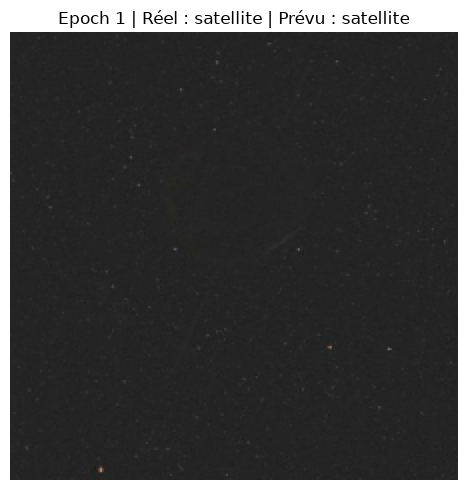

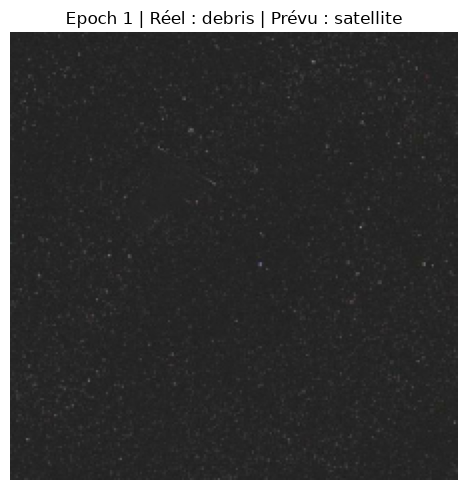

140/140 ━━━━━━━━━━━━━━━━━━━━ 279s 2s/step - accuracy: 0.7894 - loss: 1.1702 - val_accuracy: 0.8619 - val_loss: 0.4253
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7693 - loss: 0.5873Epoch 2 - détections validation : satellite=223, debris=16


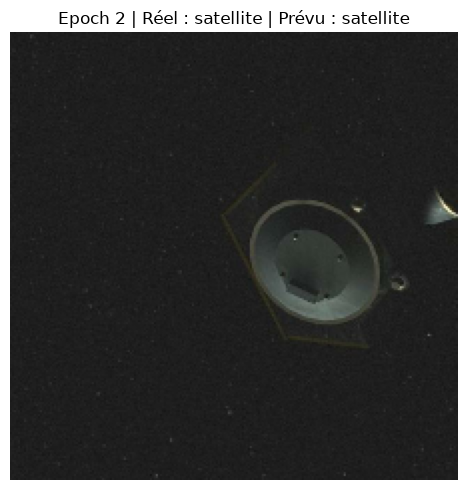

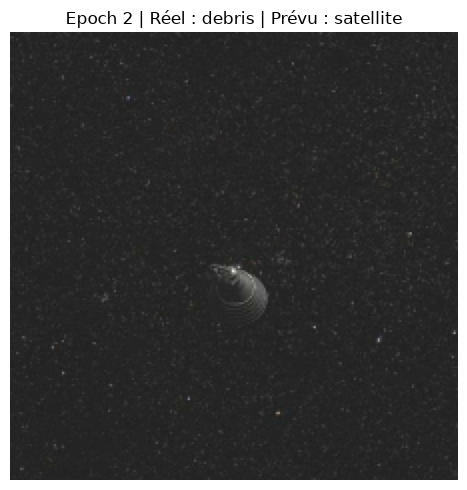

140/140 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - accuracy: 0.7693 - loss: 0.5873 - val_accuracy: 0.8410 - val_loss: 0.3726
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8360 - loss: 0.4202Epoch 3 - détections validation : satellite=187, debris=52


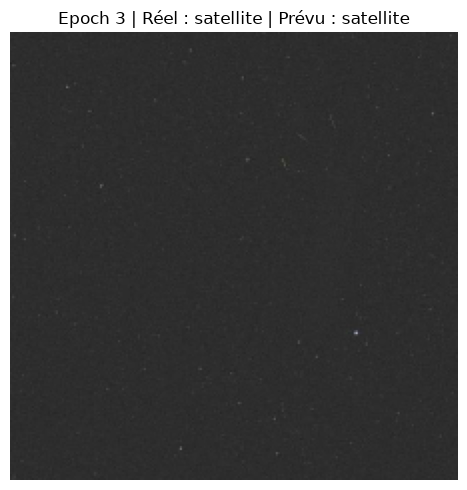

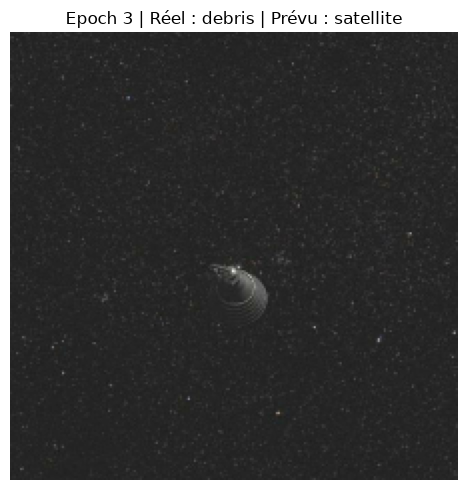

140/140 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - accuracy: 0.8360 - loss: 0.4202 - val_accuracy: 0.7741 - val_loss: 0.5336
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8450 - loss: 0.3577Epoch 4 - détections validation : satellite=181, debris=58


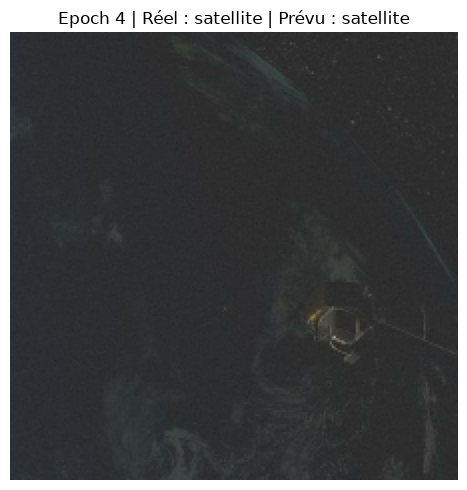

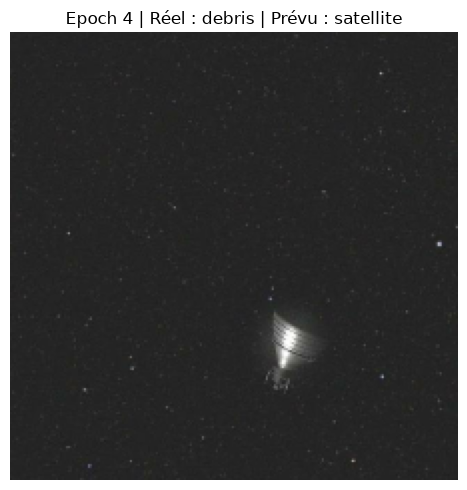

140/140 ━━━━━━━━━━━━━━━━━━━━ 240s 2s/step - accuracy: 0.8450 - loss: 0.3577 - val_accuracy: 0.7364 - val_loss: 0.5096
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8678 - loss: 0.3260Epoch 5 - détections validation : satellite=183, debris=56


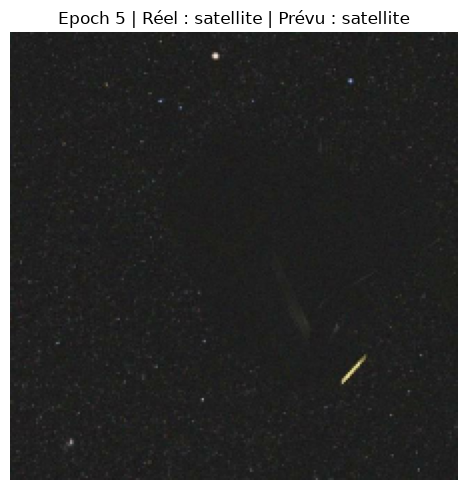

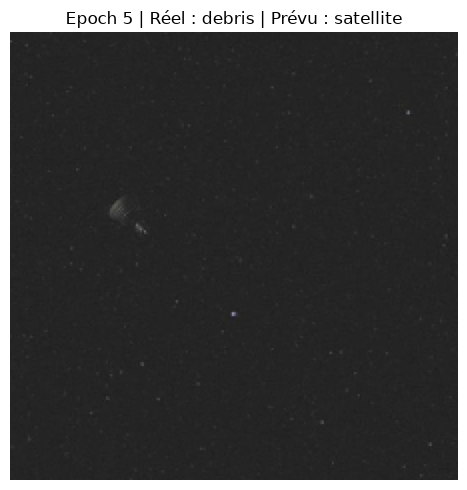

140/140 ━━━━━━━━━━━━━━━━━━━━ 258s 2s/step - accuracy: 0.8678 - loss: 0.3260 - val_accuracy: 0.7573 - val_loss: 0.6779
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8804 - loss: 0.3105Epoch 6 - détections validation : satellite=190, debris=49


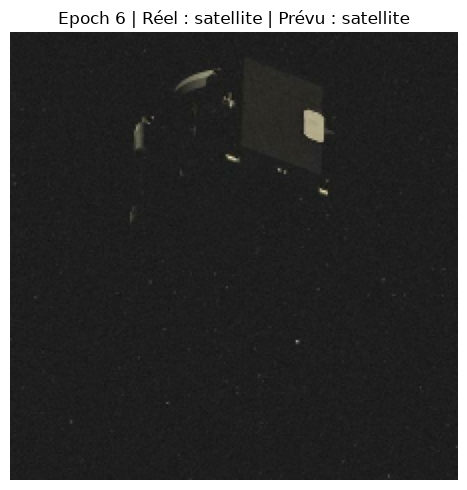

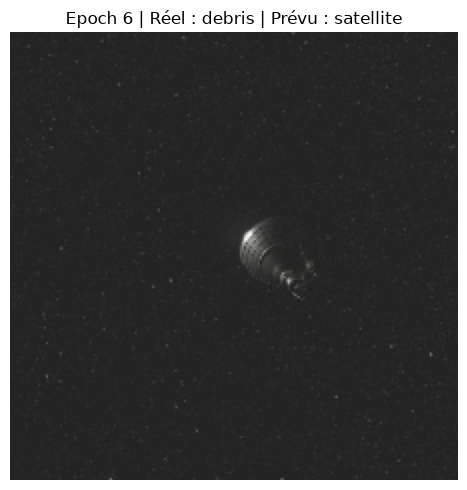

140/140 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - accuracy: 0.8804 - loss: 0.3105 - val_accuracy: 0.7657 - val_loss: 0.6275
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8423 - loss: 0.3639Epoch 7 - détections validation : satellite=171, debris=68


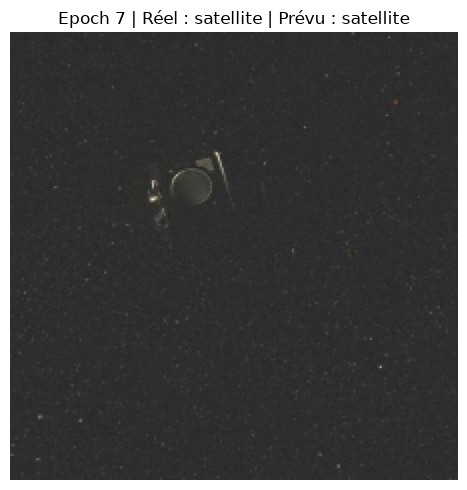

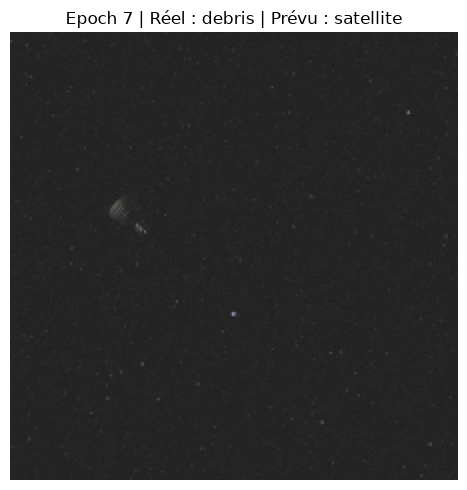

140/140 ━━━━━━━━━━━━━━━━━━━━ 245s 2s/step - accuracy: 0.8423 - loss: 0.3639 - val_accuracy: 0.6946 - val_loss: 0.6424
Modèle ImageNet sauvegardé dans : models_apres/satellite_debris_best_CosineDecay_1e-1__2.keras


In [11]:
from pathlib import Path
from tensorflow import keras

NEXT_MODEL_PATH = Path("models_apres/satellite_debris_best_CosineDecay_1e-1__2.keras")
NEXT_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

NB_EPOCHS = 10

base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights=None,
)
base_model.trainable = True

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=True)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.3)(x)
outputs = keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="class_output",
)(x)
model = keras.Model(inputs, outputs)

steps_per_epoch = len(df_train_5050) // BATCH_SIZE
total_steps = steps_per_epoch * NB_EPOCHS

learning_rate = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-1,
    decay_steps=total_steps,
    alpha=1e-2,
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)


checkpoint = keras.callbacks.ModelCheckpoint(
    NEXT_MODEL_PATH,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=6,
    restore_best_weights=True,
)

epoch_preview = EpochPreviewCallback(val_classification_ds, CLASS_NAMES)

history = model.fit(
    train_classification_ds,
    validation_data=val_classification_ds,
    epochs=NB_EPOCHS,
    callbacks=[
    checkpoint,
    early_stopping,
    epoch_preview,
    wandb_callback
])
print(f"Modèle ImageNet sauvegardé dans : {NEXT_MODEL_PATH}")


## 8. Visualisation des courbes d'apprentissage

Les courbes permettent de comparer les performances sur les données d'entraînement et de validation.

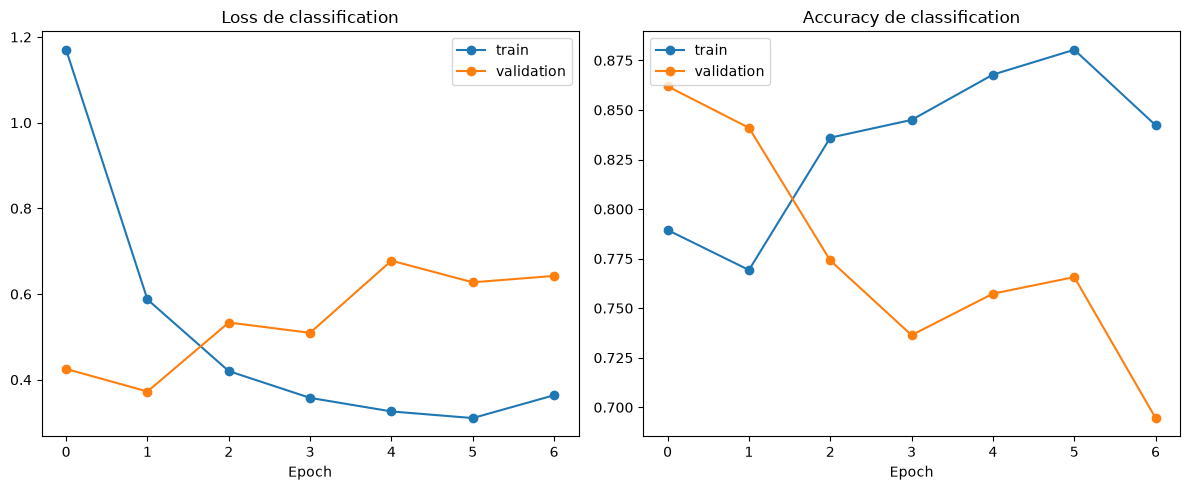

In [12]:
metrics = history.history

figure, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history.epoch, metrics["loss"], "o-", label="train")
axes[0].plot(history.epoch, metrics["val_loss"], "o-", label="validation")
axes[0].set_title("Loss de classification")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.epoch, metrics["accuracy"], "o-", label="train")
axes[1].plot(history.epoch, metrics["val_accuracy"], "o-", label="validation")
axes[1].set_title("Accuracy de classification")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Évaluation finale sur le jeu de test

Le jeu de test n'est pas utilisé pour modifier le modèle. Il sert uniquement à mesurer ses performances sur des images qu'il n'a pas vues pendant l'entraînement.

In [13]:
test_results = model.evaluate(test_classification_ds, return_dict=True)

print("Résultats de classification sur le jeu de test :")
for metric_name, metric_value in test_results.items():
    print(f"{metric_name}: {metric_value:.4f}")


8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 477ms/step - accuracy: 0.8699 - loss: 0.4486
Résultats de classification sur le jeu de test :
accuracy: 0.8699
loss: 0.4486


In [14]:
# from pathlib import Path
# from tensorflow import keras

# MODEL_DIR = Path("models")
# model_paths = sorted(MODEL_DIR.glob("*.keras"))

# if not model_paths:
#     raise FileNotFoundError(f"Aucun modèle .keras trouvé dans {MODEL_DIR.resolve()}")

# validation_results = []

# for model_path in model_paths:
#     print(f"Évaluation de {model_path.name}...")
#     candidate_model = keras.models.load_model(model_path)
#     balanced_metrics = candidate_model.evaluate(
#         val_classification_ds,
#         return_dict=True,
#         verbose=0,
#     )
#     original_metrics = candidate_model.evaluate(
#         val_original_classification_ds,
#         return_dict=True,
#         verbose=0,
#     )
#     validation_results.append({
#         "model": model_path.name,
#         "balanced_accuracy": float(balanced_metrics["accuracy"]),
#         "balanced_loss": float(balanced_metrics["loss"]),
#         "original_accuracy": float(original_metrics["accuracy"]),
#         "original_loss": float(original_metrics["loss"]),
#     })

# validation_results.sort(key=lambda result: result["balanced_accuracy"], reverse=True)

# print("\nClassement des modèles sur les données de validation :")
# for rank, result in enumerate(validation_results, start=1):
#     print(
#         f"{rank}. {result['model']} | "
#         f"équilibrée accuracy={result['balanced_accuracy']:.4f} | "
#         f"équilibrée loss={result['balanced_loss']:.4f} | "
#         f"originale accuracy={result['original_accuracy']:.4f} | "
#         f"originale loss={result['original_loss']:.4f}"
#     )

# validation_ranking = pd.DataFrame(validation_results)
# validation_ranking


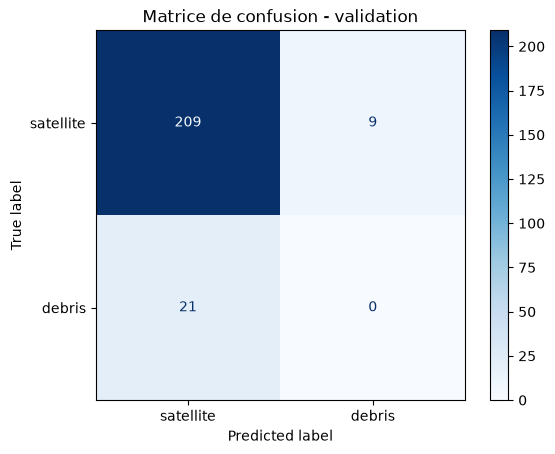

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = []
y_pred = []

for images, labels in val_classification_ds:
    predictions = model.predict(images, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
)

display.plot(cmap="Blues")
plt.title("Matrice de confusion - validation")
plt.show()